# CS351 - AI

## Lab 01: Linear Regression with One Variable

### Lab Objectives

By the end of this lab, you will be able to:

* Use basic Python libraries for Machine Learning.
* Create and work with NumPy arrays.
* Load and inspect a simple dataset.
* Visualize data using Matplotlib.
* Implement a simple linear regression model.
* Calculate the cost function.
* Calculate gradients.
* Apply gradient descent to find better values of `w` and `b`.
* Visualize the final regression line.
* Make predictions using the trained model.

### Libraries Used

| Library      | Purpose                                       |
| ------------ | --------------------------------------------- |
| NumPy        | Numerical calculations and arrays             |
| Matplotlib   | Data visualization                            |
| Pandas       | Data handling (introduced briefly)            |
| Scikit-learn | Ready-made ML algorithms|

In this lab, we will mainly use **NumPy** and **Matplotlib**.


## 1. Importing Libraries

Machine Learning involves a lot of numerical calculations and data visualization.

We will use:

* **NumPy (`numpy`)** → arrays and mathematical calculations
* **Matplotlib (`matplotlib`)** → graphs and visualization

The common abbreviations are `np` and `plt`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x = np.array([1, 2, 3, 4, 5])

print("x =", x)
print("Mean =", np.mean(x))
print("Sum =", np.sum(x))
print("Shape =", x.shape)

x = [1 2 3 4 5]
Mean = 3.0
Sum = 15
Shape = (5,)


### Practice

Try changing the values in `x`.

Then calculate:

1. The mean
2. The sum
3. The maximum value
4. The minimum value


## 2. NumPy Arrays

In Machine Learning, datasets are commonly stored as arrays.

For example:

`x` can contain input values.

`y` can contain the corresponding output values.

Example:

```text
x = [1, 2, 3, 4]
y = [2, 4, 6, 8]
```

Here, each `x` value has a corresponding `y` value.


In [3]:
x = np.array([1, 2, 3, 4])
y = np.array([2, 4, 6, 8])

print("x:", x)
print("y:", y)

print("First x value:", x[0])
print("First y value:", y[0])

print("Number of examples:", len(x))

x: [1 2 3 4]
y: [2 4 6 8]
First x value: 1
First y value: 2
Number of examples: 4


In [4]:
print(x[1])

2


### Practice

What do you think these will print?

```python
x[1]
x[2]
y[3]
```

Run the code and check your answer.


## 3. Dataset

Suppose we want to decide where to open a new restaurant.

We have data about:

* **Population of a city**
* **Profit of a restaurant in that city**

Our goal is to learn whether population can help us predict restaurant profit.

We will use a small dataset containing two columns:

```text
Population, Profit
```

Each row represents one city.


In [5]:
# Create a simple dataset
data = np.array([
    [1, 2],
    [2, 4],
    [3, 5],
    [4, 8],
    [5, 10],
    [6, 11],
    [7, 14],
    [8, 16],
    [9, 17],
    [10, 20]
])

print(data)

[[ 1  2]
 [ 2  4]
 [ 3  5]
 [ 4  8]
 [ 5 10]
 [ 6 11]
 [ 7 14]
 [ 8 16]
 [ 9 17]
 [10 20]]


In [6]:
# Separate the input and output

x_train = data[:, 1]
y_train = data[:, 1]

print("x_train:", x_train[:5])
print("y_train:", y_train[:5])

x_train: [ 2  4  5  8 10]
y_train: [ 2  4  5  8 10]


In [7]:
print("Shape of x_train:", x_train.shape)
print("Shape of y_train:", y_train.shape)
print("Number of training examples:", len(x_train))

Shape of x_train: (10,)
Shape of y_train: (10,)
Number of training examples: 10


## 4. Visualizing the Data

Before building a Machine Learning model, it is useful to visualize the data.

We will use a **scatter plot**.

* X-axis → Population
* Y-axis → Profit


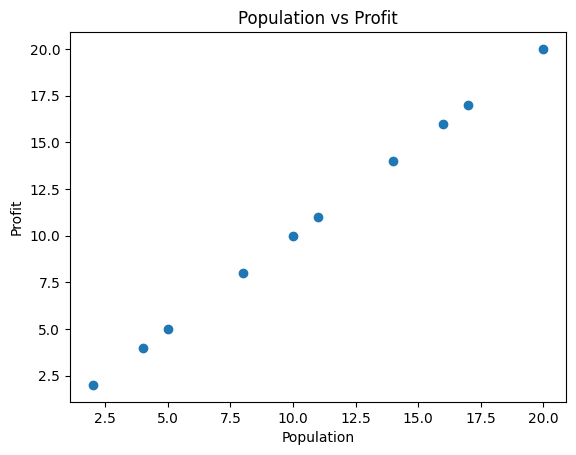

In [8]:
plt.scatter(x_train, y_train)

plt.xlabel("Population")
plt.ylabel("Profit")
plt.title("Population vs Profit")

plt.show()

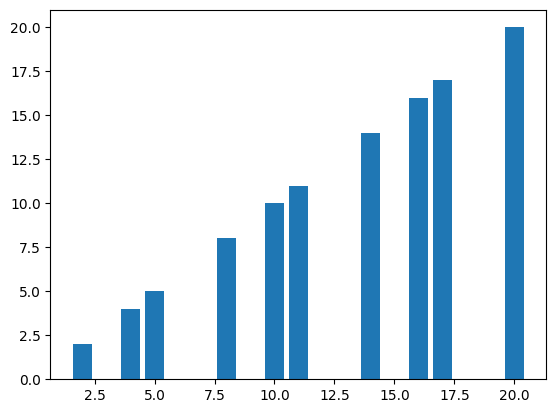

In [9]:
plt.bar(x_train, x_train)
plt.show()

### Think About It



Do you notice a general relationship between population and profit?

We will try to represent this relationship using a straight line.


## 5. Linear Regression Model

For linear regression with one variable:

**f(x) = wx + b**

Where:

* `x` = input feature
* `w` = weight/slope
* `b` = bias/intercept
* `f(x)` = prediction

Our model tries to find good values of `w` and `b`.

Different values of `w` and `b` produce different lines.


In [10]:
w = 1
b = 0

prediction = w * x_train + b

print("First five predictions:")
print(prediction[:5])

First five predictions:
[ 2  4  5  8 10]


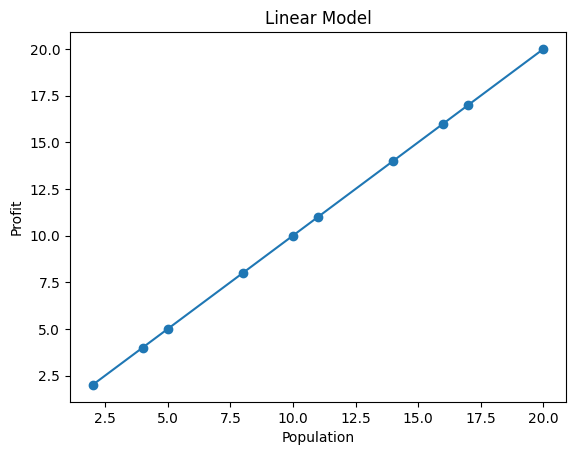

In [11]:
plt.scatter(x_train, y_train)
plt.plot(x_train, prediction)

plt.xlabel("Population")
plt.ylabel("Profit")
plt.title("Linear Model")

plt.show()

### Experiment

Change the values of `w` and `b`.

Try:

```python
w = 1
b = 0
```

Then:

```python
w = 2
b = 0
```

Then:

```python
w = 1
b = 5
```

Observe how changing `w` and `b` changes the line.


## 6. Cost Function

A line can be good or bad depending on how close its predictions are to the actual values.

The cost function measures this error.

For linear regression:

**J(w,b) = 1/(2m) × Σ(f(x) − y)²**

Where:

* `m` = number of training examples
* `f(x)` = predicted value
* `y` = actual value

A **smaller cost means the predictions are generally closer to the actual values**.


In [12]:
def compute_cost(x, y, w, b):
    m = len(x)

    predictions = w * x + b
    errors = predictions - y

    cost = (1 / (2 * m)) * np.sum(errors ** 2)

    return cost

In [13]:
w = 1
b = 0

cost = compute_cost(x_train, y_train, w, b)

print("Cost:", cost)

Cost: 0.0


### Practice

Try different values of `w` and `b`.

Find values that give a **smaller cost** than your first result.

You do not need to find the best values manually.
